# 05 | Teaching simulations: from Fisher–KPP in tissue to graph dynamics

**All concentrations, injury severities and dynamical predictions in this notebook are simulated.** Anatomy and baseline SC are patient-derived. No tumour growth rate, resection extent or cognitive outcome is fitted.

**Primary FC stability:** notebook 14 recommends 97 distinct frames per session from nonreplacement ten-frame blocks, with complete WM/CSF nuisance refitting. These equal-duration subset ranges are conditional stability summaries, not full-run confidence intervals. The observed full-run points remain unchanged. Notebooks 10/11/13 retain earlier bootstrap, matching and mechanism analyses as sensitivities. See `config/PRIMARY_FC_RESAMPLING.md`. **Current SC policy:** graphs, network means and simulations use each session's 16/20 consensus with mean counts per 10,000 attempted seeds. Primary paired coupling uses the 823-edge intersection with session-specific weights. See `config/PRIMARY_SC.md`. Historical seed-160 diagnostics in notebooks 07/08 remain sensitivity analyses; notebook 09 supplies the reliability evidence. Notebook 10 quantifies joint seed/FC sampling under this policy, including matched designs and support reselection. Notebook 11 extends the full-run branch to paired nuisance refits; notebook 12 integrates all clinical/context fields with network uncertainty. Notebook 13 diagnoses PCA-training shifts and compares nonreplacement blocks at matched distinct counts and 80% retention. The rule is post hoc and does not validate anatomy or a surgical/cognitive effect.

In [1]:
from pathlib import Path
import os, sys, json
root = Path.cwd() if (Path.cwd()/"pyproject.toml").exists() else Path.cwd().parent
os.environ.setdefault("MPLCONFIGDIR", str(root/".cache/matplotlib"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, Markdown, Image
from pat16 import ROOT, DATA, RESULTS, SESSIONS
from pat16.connectivity import labels
from pat16.primary_sc import load_weights
nodes = pd.read_csv(RESULTS/"nodes.csv")
summary = json.loads((RESULTS/"summary.json").read_text())
plt.rcParams.update({"figure.figsize": (9,4), "font.size": 10})


## A network analogue of reaction–diffusion
The previous project models cell concentration in 3D tissue. A graph analogue is $\dot c=-D Lc+\rho c(1-c)$, where $L$ is the weighted graph Laplacian. It illustrates network-mediated spread and logistical growth; it is not a validated model of glioma migration along these streamlines. Space, vascular supply and local infiltration are omitted; time is arbitrary.

A hypothetical lesion scales each edge by endpoint survival: $W'_{ij}=(1-s e_i)W_{ij}(1-s e_j)$, where $e_i=\exp(-d_i/10\,\mathrm{mm})$ uses the minimum parcel-to-pre-op-lesion distance. This is a scenario rule, **not an observed postoperative cavity or a surgical plan**.

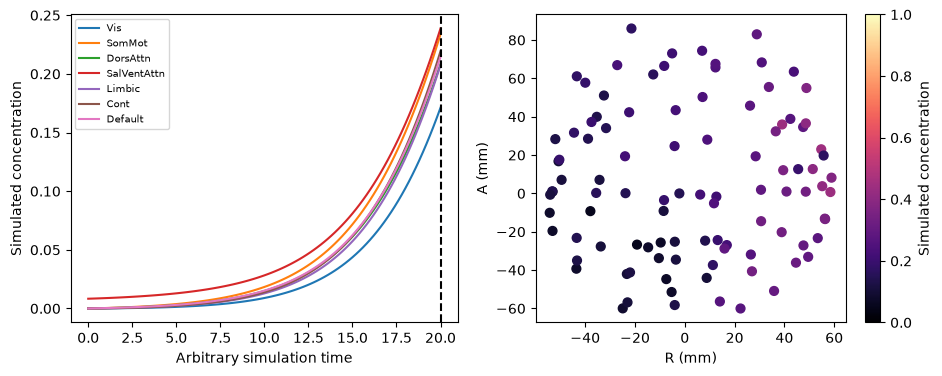

interactive(children=(FloatSlider(value=0.5, description='diffusion', max=1.0), FloatSlider(value=0.3, descrip…

<function __main__.growth_view(diffusion=0.5, rho=0.3, time=100)>

In [2]:
from pat16.networks import graph_growth,attenuate,ou_fc,metrics
baseline=load_weights("preop");exposure=np.exp(-nodes.distance_to_lesion_mm.to_numpy()/10)
seed=int(nodes.lesion_overlap_fraction.argmax())

def growth_view(diffusion=.5,rho=.3,time=100):
    h=graph_growth(baseline,seed,steps=100,dt=.2,diffusion=diffusion,rho=rho)
    fig,axs=plt.subplots(1,2,figsize=(11,4))
    for name in dict.fromkeys(nodes.network):axs[0].plot(np.arange(101)*.2,h[:,nodes.network==name].mean(1),label=name)
    axs[0].axvline(time*.2,color="black",ls="--");axs[0].set_xlabel("Arbitrary simulation time");axs[0].set_ylabel("Simulated concentration");axs[0].legend(fontsize=7)
    pts=axs[1].scatter(nodes.x,nodes.y,c=h[time],cmap="magma",vmin=0,vmax=1,s=40);fig.colorbar(pts,ax=axs[1],label="Simulated concentration");axs[1].set_xlabel("R (mm)");axs[1].set_ylabel("A (mm)");plt.show()
widgets.interact(growth_view,diffusion=widgets.FloatSlider(min=0,max=1,step=.1,value=.5),rho=widgets.FloatSlider(min=0,max=.6,step=.05,value=.3),time=widgets.IntSlider(min=0,max=100,value=100))

## From structure to fluctuating activity
An Ornstein–Uhlenbeck (OU) network obeys $d x=A x\,dt+dB$, with $A=-I+gW/\lambda_{max}(W_{pre})$ and $0\le g<1$. Stationary covariance solves $A\Sigma+\Sigma A^T+I=0$. Normalize covariance to obtain model FC.

This linear, symmetric model has no BOLD haemodynamics, conduction delays, inhibition, neural adaptation or cognition. Its nonnegative SC cannot explain the full signed empirical FC. The baseline spectral scale stays fixed across injury severities; otherwise independent renormalization could hide damage.

Hypothetical efficiency / baseline = 0.816; gain = 0.60


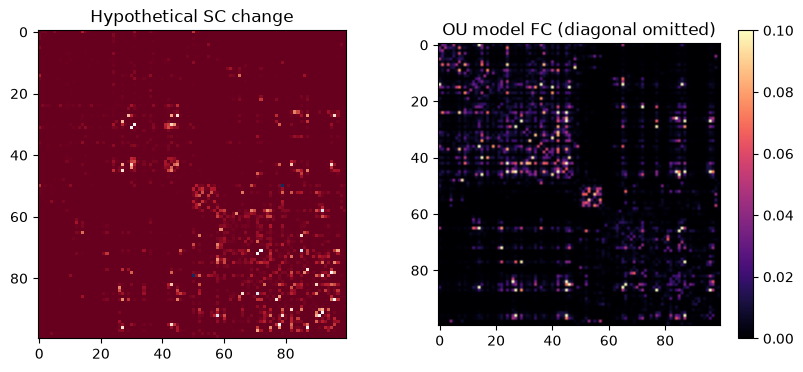

interactive(children=(FloatSlider(value=0.5, description='severity', max=1.0, step=0.05), FloatSlider(value=0.…

<function __main__.injury_view(severity=0.5, gain=0.6)>

In [3]:
def injury_view(severity=.5,gain=.6):
    injured=attenuate(baseline,exposure,severity);scale=baseline.max();rho=max(np.linalg.eigvalsh(baseline).max(),1e-12)
    pred=ou_fc(injured,gain,scale=rho)
    ratio=metrics(injured,1,scale)["weighted_global_efficiency"]/metrics(baseline,1,scale)["weighted_global_efficiency"]
    print(f"Hypothetical efficiency / baseline = {ratio:.3f}; gain = {gain:.2f}")
    fig,axs=plt.subplots(1,2,figsize=(10,4));axs[0].imshow(injured-baseline,cmap="RdBu_r");axs[0].set_title("Hypothetical SC change")
    im=axs[1].imshow(pred-np.eye(100),vmin=0,vmax=.1,cmap="magma");axs[1].set_title("OU model FC (diagonal omitted)");fig.colorbar(im,ax=axs[1]);plt.show()
widgets.interact(injury_view,severity=widgets.FloatSlider(min=0,max=1,step=.05,value=.5),gain=widgets.FloatSlider(min=0,max=.95,step=.05,value=.6))

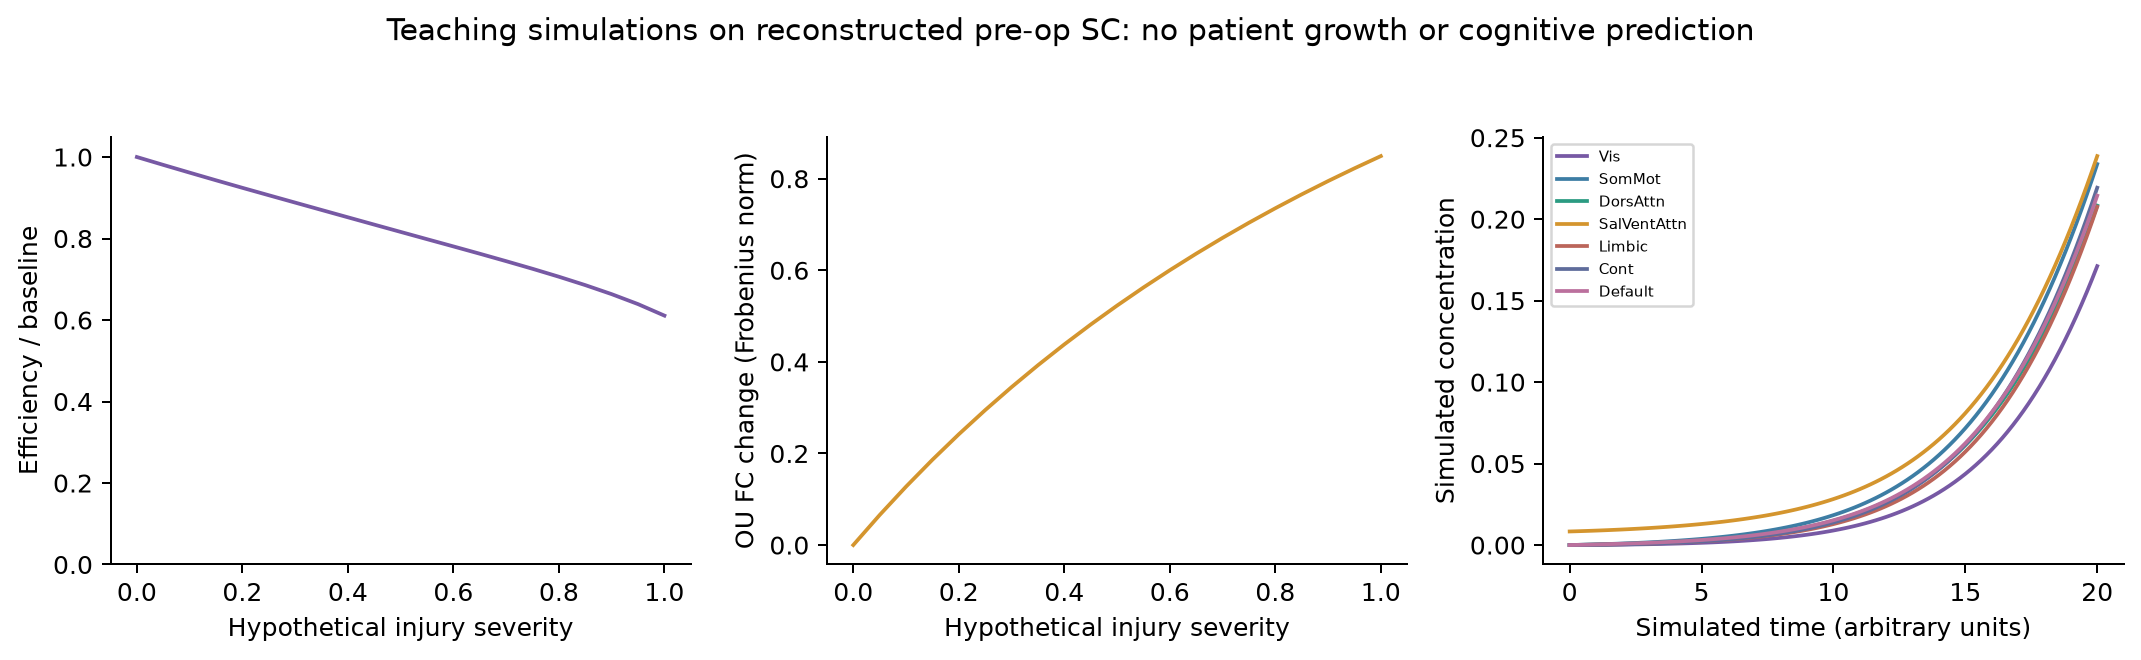

,severity,relative_efficiency,OU_fc_change_frobenius
0,0.00,1.000000,0.000000
5,0.25,0.906238,0.294655
10,0.50,0.816213,0.522888
15,0.75,0.725691,0.703829
20,1.00,0.610787,0.849352


In [4]:
display(Image(filename=str(RESULTS/"figures/simulations.png")))
display(pd.read_csv(RESULTS/"simulation_lesion_sweep.csv").iloc[::5])

## Exercise: loss, preservation and compensation
Set gain to zero: FC becomes the identity regardless of SC. Set severity to zero: recover baseline. At full severity only exposed edges attenuate. Can two networks with similar global efficiency have different FC? Which predictions change if injury acts on edges traversing the lesion instead of endpoints?

A future model may compare pressure release, fibre injury and plasticity scenarios against independent observations. This notebook supplies mechanisms to question, not evidence that a chosen mechanism explains PAT16.